In [1]:
import numpy as np
import pandas as pd
import get_klines
import treatment
import anual_factor
import coef_t_stat
import momentum_reversal

In [2]:
px,vol = get_klines.find_existing_file("30m", "2017-01-01", "2026-10-01", 1000, "vol")
ret=px.pct_change()

Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_vol.pk
Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_px.pk


In [3]:
def z_score(df):
    mu = np.nanmean(df, axis=1, keepdims=True)
    sd = np.nanstd(df, axis=1, ddof=1, keepdims=True)
    return (df - mu) / sd

In [4]:
ret_z = z_score(ret)

C:\Users\parra\AppData\Local\Temp\ipykernel_3708\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [5]:
ret_z

,BTCUSDT,USDCUSDT,ETHUSDT,SOLUSDT,BNBUSDT,ZECUSDT,PEPEUSDT,NEARUSDT,XRPUSDT,TRXUSDT,...,USDSOLDUSDT,BTTUSDT,USDSBUSDT,HCUSDT,BCHSVUSDT,ERDUSDT,VENUSDT,STORMUSDT,PAXUSDT,BCHABCUSDT
open_time,,,,,,,,,,,,,,,,,,,,,
2017-08-17 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 04:30:00+00:00,0.707107,NaN,-0.707107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:00:00+00:00,0.707107,NaN,-0.707107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:30:00+00:00,-0.707107,NaN,0.707107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 06:00:00+00:00,-0.707107,NaN,0.707107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09 22:00:00+00:00,0.136076,0.165582,0.274543,0.270529,-0.407287,-0.826268,-0.316000,0.008557,0.220327,0.280431,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 22:30:00+00:00,-0.339568,-0.621286,-0.419514,-0.393624,0.006770,-0.303414,-0.091845,2.674929,-0.383521,-0.752368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 23:00:00+00:00,-0.491580,-0.456505,-0.447825,-0.410798,-0.337279,-0.432600,-0.458231,-0.913546,-0.482979,-0.510224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Momentum

In [6]:
import momentum_reversal_gpu

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [12]:
momentum_reversal_gpu.main(10*24*2, ret_z, "betas_zscore")

In [7]:
g = momentum_reversal_gpu.load_wide("gamma","betas_zscore")                  # time x k

In [8]:
gamma_k = g.mean(axis=0)
gamma_mean = gamma_k/gamma_k.abs().sum()

In [25]:
gamma_mean.to_csv("gamma_mean_z_score.csv")

In [39]:
gamma_mean

1     -0.202973
2     -0.040828
3     -0.033537
4     -0.015379
5     -0.013458
         ...   
476    0.002131
477    0.000891
478    0.002808
479    0.001478
480    0.004874
Length: 480, dtype: float32

In [14]:
gamma_mean = pd.read_csv("gamma_mean_z_score.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'gamma_mean_z_score.csv'

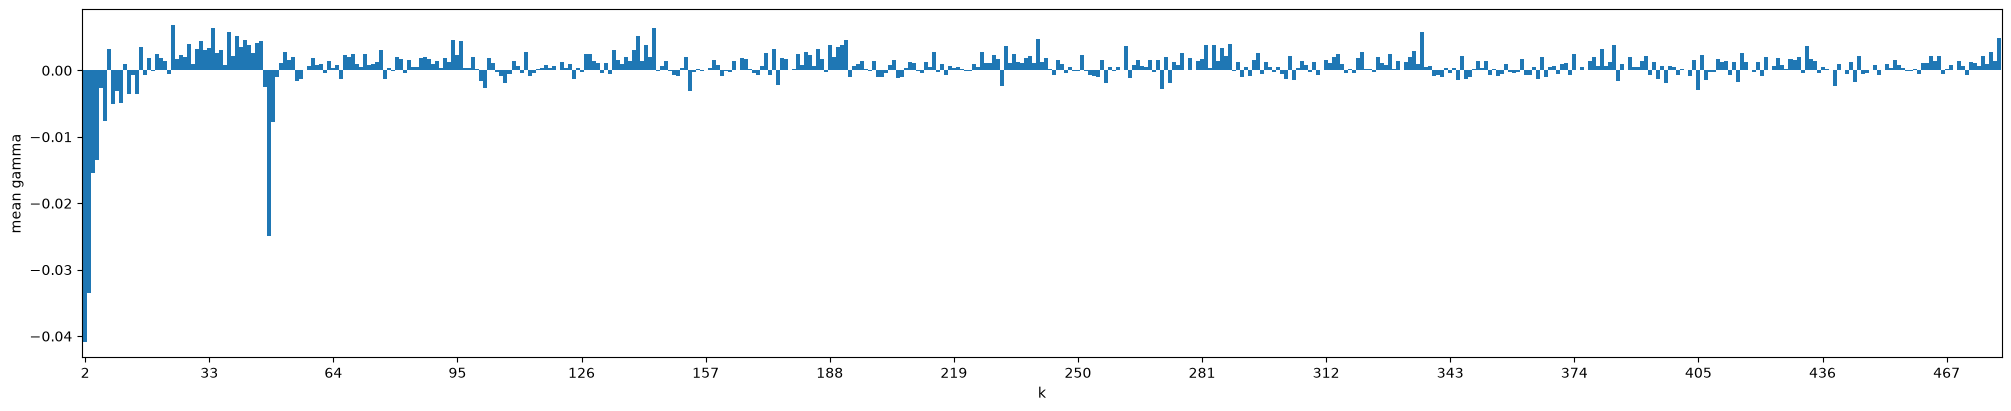

In [9]:
import matplotlib.pyplot as plt

s = gamma_mean[1:]       # iloc makes the slice explicitly positional

fig, ax = plt.subplots(figsize=(min(max(6, len(s) * 0.1), 20), 4),
                       layout="constrained")
s.plot.bar(ax=ax, width=1.0, xlabel="k", ylabel="mean gamma")

step = max(1, len(s) // 15)        # about 15 labels, whatever the length
ax.set_xticks(range(0, len(s), step))
ax.set_xticklabels(s.index[::step], rotation=0)
plt.show()

In [11]:
z = ret_z.clip(ret_z.quantile(.01, axis=1), ret_z.quantile(.99, axis=1), axis=0)
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)

# Factors

In [12]:
rev = sum(gamma_mean[k] * z.shift(k) for k in range(1, 467) if gamma_mean[k] < 0)    # lags 1-15
mom = sum(gamma_mean[k] * z.shift(k) for k in range(16, 467) if gamma_mean[k] > 0)   # lags 16-46

In [13]:
size = np.log(vol.rolling(4).mean()).shift(1)

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\pandas\core\internals\blocks.py:354: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


In [15]:
rev.to_pickle("rev.pkl")
mom.to_pickle("mom.pkl")
size.to_pickle("size.pkl")

# Strategy

In [42]:
import q_quantile_factor_gpu

In [43]:
factors = {"rev": rev, "mom": mom, "size": size}
coefs = q_quantile_factor_gpu.factor_regression(ret, factors)

In [39]:
results=coef_t_stat.t_stat(coefs)
results

,mean,t_mean,rho,t_rho,R2,n
const,-0.000033,-2.113922,-0.021446,-0.607186,0.000460,131478.0
rev,0.000697,77.861948,-0.087808,-3.249902,0.007710,131478.0
mom,0.000048,10.338986,0.052949,8.560713,0.002804,131478.0
size,-0.000036,-13.673063,0.075625,10.964531,0.005719,131478.0


In [28]:
import multi_linear_strat

In [29]:
factors_z = {"rev": z_score(rev), "mom": z_score(mom), "size": -z_score(size)}

C:\Users\parra\AppData\Local\Temp\ipykernel_10224\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\parra\AppData\Local\Temp\ipykernel_10224\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [30]:
net,bt = multi_linear_strat.main(ret, factors_z)

This is the new update


<Axes: title={'center': 'Cumulative Net Value'}, xlabel='open_time'>

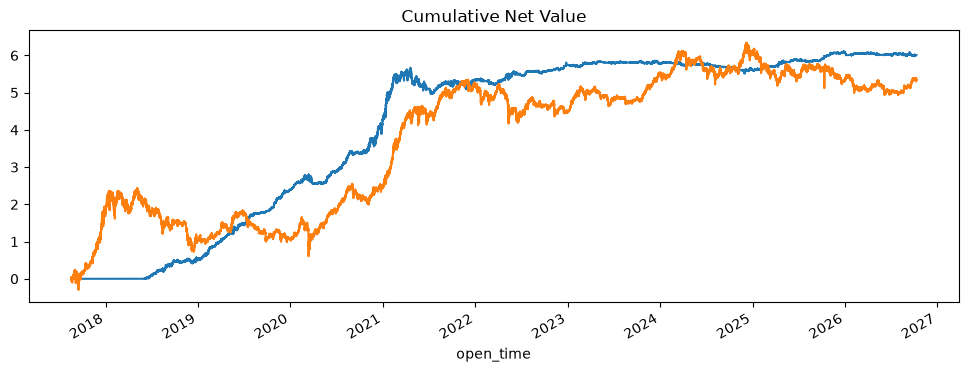

In [34]:
net.cumsum().plot(figsize=(12, 4), title="Cumulative Net Value")
ret.mean(axis=1).cumsum().plot()

In [32]:
multi_linear_strat.summarize(bt)

{'gross_ann': np.float64(0.6574903725071456),
 'gross_sharpe': np.float64(1.6940626382234996),
 'turnover/bar': np.float64(0.06795574571127247),
 'breakeven_bp': np.float64(5.522415934893925)}

# Kalman Filter

In [9]:
factors = {"rev": rev, "mom": mom, "size": size}

## Observation matrix

In [14]:
rev

,BTCUSDT,USDCUSDT,ETHUSDT,SOLUSDT,BNBUSDT,ZECUSDT,PEPEUSDT,NEARUSDT,XRPUSDT,TRXUSDT,...,USDSOLDUSDT,BTTUSDT,USDSBUSDT,HCUSDT,BCHSVUSDT,ERDUSDT,VENUSDT,STORMUSDT,PAXUSDT,BCHABCUSDT
open_time,,,,,,,,,,,,,,,,,,,,,
2017-08-17 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 04:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09 22:00:00+00:00,0.121949,0.116906,0.093308,0.171099,0.085776,-0.008182,0.012500,-0.632107,0.076973,0.141227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 22:30:00+00:00,-0.003868,-0.001386,-0.036532,-0.021821,0.110258,0.196277,0.054243,-0.174313,-0.049238,-0.024077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 23:00:00+00:00,0.110898,0.166994,0.108919,0.121360,0.044434,0.108705,0.032691,-0.697649,0.074837,0.196730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
import cupy as cp
import numpy as np
import pandas as pd

CH, MIN_OBS = 20000, 30
sigs  = {"rev": rev, "mom": mom, "size": size}
names = list(sigs)
K     = len(names) + 1

ret_n = ret.to_numpy(np.float32)
sig_n = [sigs[n].reindex_like(ret).to_numpy(np.float32) for n in names]   # same index/columns as ret
T, N  = ret_n.shape

#lam_out = np.full((T, K), np.nan)
#V_out   = np.full((T, K, K), np.nan)
cy = np.full((T, K), np.nan)

for s in range(0, T, CH):
    e = min(s + CH, T)
    y = cp.asarray(ret_n[s:e], dtype=cp.float64)                              # (c, N)
    # y = gpu_clip(y, 0.01)   # optional: winsorize returns as in your factor_regression
    X = cp.stack([cp.asarray(g[s:e], dtype=cp.float64) for g in sig_n], axis=2)   # (c, N, F)

    m = cp.isfinite(y) & cp.isfinite(X).all(axis=2)                           # valid coins
    H = cp.concatenate([cp.ones_like(y)[:, :, None], X], axis=2)              # (c, N, K)
    H = cp.where(m[:, :, None], H, 0.0)
    y = cp.where(m, y, 0.0)

    Ht  = H.transpose(0, 2, 1)                                                # (c, K, N)
    HtH = Ht @ H                                                              # (c, K, K)
    Hty = Ht @ y[:, :, None]                                                  # (c, K, 1)

    n  = m.sum(axis=1)
    ok = n >= MIN_OBS                                                         # enough observations for regression
    HtH = cp.where(ok[:, None, None], HtH, cp.eye(K))                         # avoids singular matrices

    HTH_inv = cp.linalg.inv(HtH)                                              # (c, K, K)
    cy[s:e] = cp.asnumpy(cp.where(ok[:, None], (HTH_inv @ Hty)[:,:,0], cp.nan))                      # (c, K, 1)

    #lam_out[s:e] = cp.asnumpy(cp.where(ok[:, None], lam, cp.nan))
    #V_out[s:e]   = cp.asnumpy(cp.where(ok[:, None, None], V, cp.nan))
    del y, X, H, Ht, HtH, Hty
    cp.get_default_memory_pool().free_all_blocks()

In [24]:
cy = pd.DataFrame(cy, index=ret.index, columns=["intercept"] + names)

In [26]:
cy.to_pickle("cy.pkl")

In [28]:
def kalman_filter(y, x_0, P_0, Q, R, F, H):
    x_prior = pd.DataFrame(index=y.index, columns=x_0.index) #T x K  
    P_prior = pd.DataFrame(index=y.index, columns=x_0.index) #T x K x K
    x_prior.loc[y.index[0]] = F @ x_0
    P_prior.loc[y.index[0]] = F @ P_0 @ F.T + Q 

    error = pd.DataFrame(index=y.index,columns="error")
    S = pd.DataFrame(index=y.index,columns="Covariance")
    K = pd.DataFrame(index=y.index,columns=x_0.index)
    x = pd.DataFrame(index=y.index, columns=x_0.index)
    P = pd.DataFrame(index=y.index, columns=x_0.index)
    for t in y.iloc[1:].index:
        error.loc[t] = y.loc[t] - H.loc[t] @ x_prior.loc[t] #T x K
        S.loc[t] = H.loc[t] @ P_prior.loc[t] @ H.loc[t].T + R.loc[t] #T x K x K
        K.loc[t] = P_prior.loc[t] @ H.loc[t].T @ np.linalg.inv(S.loc[t]) #T x K x K
        x.loc[t] = x_prior.loc[t] + K.loc[t] @ error.loc[t] #T x K
        P.loc[t] = (np.eye(len(x_0)) - K.loc[t] @ H.loc[t]) @ P_prior.loc[t] #T x K x K

        x_prior.loc[t] = F @ x.loc[t] #T x K
        P_prior.loc[t] = F @ P.loc[t] @ F.T + Q #T x K x K 
        

In [31]:
T,K = np.shape(cy)
x_0 = pd.DataFrame(np.zeros(K),index=cy.columns)
P_0 = np.eye(K)
Q = np.eye(K)
R = np.eye(K)
F = np.eye(K)
H = np.eye(T,K)
kalman_filter(cy, x_0, P_0, Q, R, F, H)

ValueError: Incompatible indexer with DataFrame